## Data Preprocessing with Scanpy (mostly just ran through the tutorial quickly, need to understand it deeper)

In [1]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from bladder-10x_P4_3 folder into an AnnData object

In [3]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Bladder-10X_P4_3"),
#     sc.read_10x_mtx("droplet/Bladder-10X_P4_4"),
#     sc.read_10x_mtx("droplet/Bladder-10X_P7_7"),
#     sc.read_10x_mtx("droplet/Heart-10X_P7_4"),
#     sc.read_10x_mtx("droplet/Kidney-10X_P4_5"),
#     sc.read_10x_mtx("droplet/Kidney-10X_P4_6"),
#     sc.read_10x_mtx("droplet/Kidney-10X_P7_5"),
#     sc.read_10x_mtx("droplet/Liver-10X_P4_2"),
#     sc.read_10x_mtx("droplet/Liver-10X_P7_0"),
#     sc.read_10x_mtx("droplet/Liver-10X_P7_1"),
#     sc.read_10x_mtx("droplet/Lung-10X_P7_8"),
#     sc.read_10x_mtx("droplet/Lung-10X_P7_9"),
#     sc.read_10x_mtx("droplet/Lung-10X_P8_12"),
#     sc.read_10x_mtx("droplet/Lung-10X_P8_13"),
#     sc.read_10x_mtx("droplet/Mammary-10X_P7_12"),
#     sc.read_10x_mtx("droplet/Mammary-10X_P7_13"),
#     sc.read_10x_mtx("droplet/Marrow-10X_P7_2"),
#     sc.read_10x_mtx("droplet/Marrow-10X_P7_3"),
#     sc.read_10x_mtx("droplet/Muscle-10X_P7_14"),
#     sc.read_10x_mtx("droplet/Muscle-10X_P7_15"),
#     sc.read_10x_mtx("droplet/Spleen-10X_P4_7"),
#     sc.read_10x_mtx("droplet/Spleen-10X_P7_6"),
#     sc.read_10x_mtx("droplet/Thymus-10X_P7_11"),
#     sc.read_10x_mtx("droplet/Tongue-10X_P4_0"),
#     sc.read_10x_mtx("droplet/Tongue-10X_P4_1"),
#     sc.read_10x_mtx("droplet/Tongue-10X_P7_10"),
#     sc.read_10x_mtx("droplet/Trachea-10X_P8_14"),
#     sc.read_10x_mtx("droplet/Trachea-10X_P8_15")

# checking how visualizations look when bladder_droplet_annotations.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Liver-10X_P4_2"),
    sc.read_10x_mtx("../droplet/Liver-10X_P7_0"),
    sc.read_10x_mtx("../droplet/Liver-10X_P7_1"),
])

tiss.obs_names_make_unique()

tiss.obs

    reading ../droplet/Liver-10X_P4_2/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Liver-10X_P7_0/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Liver-10X_P7_1/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


""
AAACCTGAGCTACCTA-1
AAACCTGCAAGACACG-1
AAACCTGCATGCCTTC-1
AAACCTGGTATCTGCA-1
AAACGGGAGATATGGT-1
...
TTGGCAATCTTCATGT-1
TTGTAGGCAGGAATGC-1
TTTACTGCATTACGAC-1
TTTACTGGTACACCGC-1


In [4]:
tiss.obs

""
AAACCTGAGCTACCTA-1
AAACCTGCAAGACACG-1
AAACCTGCATGCCTTC-1
AAACCTGGTATCTGCA-1
AAACGGGAGATATGGT-1
...
TTGGCAATCTTCATGT-1
TTGTAGGCAGGAATGC-1
TTTACTGCATTACGAC-1
TTTACTGGTACACCGC-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [5]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

filtered out 70 cells that have less than 500 genes expressed
filtered out 9 cells that have less than 1000 counts


,n_genes,n_counts
AAACCTGAGCTACCTA-1,1854,8116.0
AAACCTGCAAGACACG-1,913,1748.0
AAACCTGCATGCCTTC-1,2234,8838.0
AAACCTGGTATCTGCA-1,690,1648.0
AAACGGGTCCGCATAA-1,705,1492.0
...,...,...
TTGGCAATCTTCATGT-1,895,1979.0
TTGTAGGCAGGAATGC-1,990,1880.0
TTTACTGCATTACGAC-1,1769,4564.0
TTTACTGGTACACCGC-1,529,1255.0


## Normalization

In [6]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)
# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [7]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


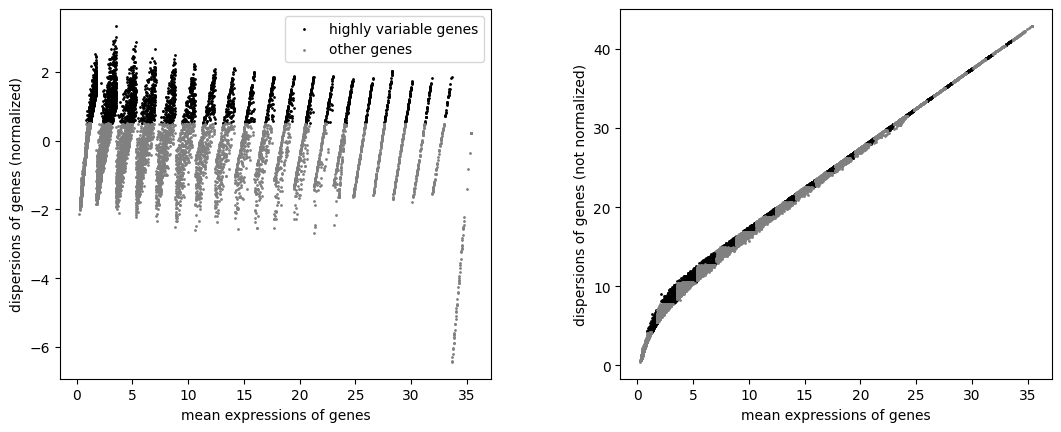

In [8]:
sc.pl.highly_variable_genes(tiss)

In [9]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
Sox17,0.005546,0.098506,True,13.980024,20.706493,0.580723
Atp6v1h,0.121289,0.379712,True,1.377528,4.585026,0.811451
Rb1cc1,0.142820,0.411293,True,1.282267,4.780643,0.949570
Rrs1,0.120820,0.389966,True,1.414418,4.699520,0.892292
Sgk3,0.051371,0.259508,True,3.445684,9.541449,2.254408
...,...,...,...,...,...,...
Arhgap6,0.021272,0.172306,True,6.517276,13.117288,0.999222
Zf12,0.001976,0.044930,True,24.512399,32.032626,1.374768
Uty,0.018087,0.156169,True,6.934146,12.999194,0.840901
Ddx3y,0.138386,0.442539,True,1.383458,4.782065,0.950575


## Dimensionality Reduction
Through PCA

In [10]:
# PCA
sc.pp.pca(tiss)
tiss.obsm['X_pca']

computing PCA
    with n_comps=50
    finished (0:00:00)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


array([[-3.4274929 , -1.0622777 ,  2.7015858 , ...,  0.65745157,
         0.6267747 ,  1.1491144 ],
       [-1.8589704 ,  0.7745872 , -0.45734748, ..., -0.4148506 ,
         1.6986221 ,  1.7134959 ],
       [ 0.20311141,  0.31648287, -1.1287766 , ..., -0.46243984,
         0.1810755 , -0.92810977],
       ...,
       [ 1.824425  ,  2.7735307 , -6.6229644 , ...,  0.7088704 ,
         1.5118495 , -1.3144156 ],
       [-6.121058  , -1.3607625 ,  6.854113  , ...,  0.87585056,
         0.04804545, -0.8144662 ],
       [-0.724761  ,  1.1613474 , -1.7649841 , ..., -0.9062806 ,
         0.58454907, -0.33299568]], shape=(1845, 50), dtype=float32)

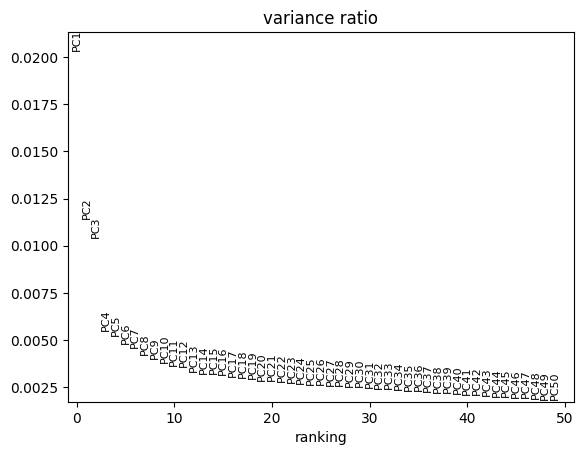

In [11]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [12]:
bladder_annotations = pd.read_csv("../annotations/Liver_droplet_annotation.csv")

y = bladder_annotations["cell_ontology_class"].values
y

array(['hepatocyte', 'hepatocyte', 'hepatocyte', ..., 'hepatocyte',
       'hepatocyte', 'hepatocyte'], shape=(1845,), dtype=object)

In [13]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

,n_genes,n_counts,cell_ontology_class
AAACCTGAGCTACCTA-1,1854,8116.0,hepatocyte
AAACCTGCAAGACACG-1,913,1748.0,hepatocyte
AAACCTGCATGCCTTC-1,2234,8838.0,hepatocyte
AAACCTGGTATCTGCA-1,690,1648.0,hepatocyte
AAACGGGTCCGCATAA-1,705,1492.0,hepatocyte
...,...,...,...
TTGGCAATCTTCATGT-1,895,1979.0,hepatocyte
TTGTAGGCAGGAATGC-1,990,1880.0,hepatocyte
TTTACTGCATTACGAC-1,1769,4564.0,hepatocyte
TTTACTGGTACACCGC-1,529,1255.0,hepatocyte


## Clustering


In [14]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10, method='gauss')

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=3.5)

tiss.obsp['distances'][0:100, 0:10].toarray()

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 26 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.       

In [15]:
#inspection based on above ouptput
tiss.obs

,n_genes,n_counts,cell_ontology_class,louvain
AAACCTGAGCTACCTA-1,1854,8116.0,hepatocyte,0
AAACCTGCAAGACACG-1,913,1748.0,hepatocyte,6
AAACCTGCATGCCTTC-1,2234,8838.0,hepatocyte,11
AAACCTGGTATCTGCA-1,690,1648.0,hepatocyte,14
AAACGGGTCCGCATAA-1,705,1492.0,hepatocyte,8
...,...,...,...,...
TTGGCAATCTTCATGT-1,895,1979.0,hepatocyte,0
TTGTAGGCAGGAATGC-1,990,1880.0,hepatocyte,12
TTTACTGCATTACGAC-1,1769,4564.0,hepatocyte,1
TTTACTGGTACACCGC-1,529,1255.0,hepatocyte,9


## Visualizing Clusters Using tSNE

computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1845 samples in 0.001s...
[t-SNE] Computed neighbors for 1845 samples in 0.037s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1845
[t-SNE] Computed conditional probabilities for sample 1845 / 1845
[t-SNE] Mean sigma: 1.024037
[t-SNE] KL divergence after 250 iterations with early exaggeration: 71.037498
[t-SNE] KL divergence after 1000 iterations: 0.903554
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:02)


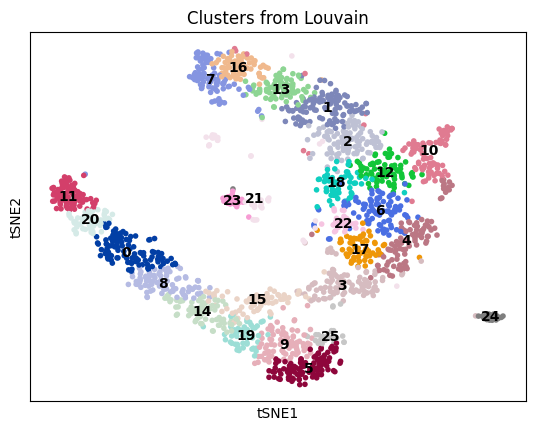

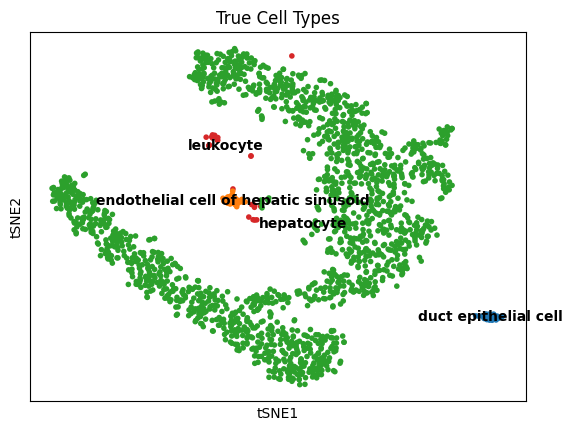

In [16]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clusters from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((1476, 4279), (369, 4279), (1476,), (369,))

## scikit-learn Machine Learning Classifiers

In [18]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [20]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

📌 Model: Logistic Regression
✅ Accuracy: 0.9973

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00       355
           3       1.00      0.50      0.67         2

    accuracy                           1.00       369
   macro avg       1.00      0.88      0.92       369
weighted avg       1.00      1.00      1.00       369

📌 Model: SVM (RBF Kernel)
✅ Accuracy: 0.9621

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.00      0.00      0.00         8
           2       0.96      1.00      0.98       355
           3       0.00      0.00      0.00         2

    accuracy                           0.96       369
   macro avg       0.24      0.25      0.25       369
weighted avg       0.93      0.96      0.94 

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Random Forest
✅ Accuracy: 0.9973

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00       355
           3       1.00      0.50      0.67         2

    accuracy                           1.00       369
   macro avg       1.00      0.88      0.92       369
weighted avg       1.00      1.00      1.00       369

📌 Model: Gradient Boosting
✅ Accuracy: 0.9973

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00       355
           3       1.00      0.50      0.67         2

    accuracy                           1.00       369
   macro avg       1.00      0.88      0.92       369
weighted avg       1.00      1.00      1.00      

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Pytorch Neural Network

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [22]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [23]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


Epoch 1, Loss: 1.4156
Epoch 2, Loss: 1.0349
Epoch 3, Loss: 0.5792
Epoch 4, Loss: 0.2697
Epoch 5, Loss: 0.1352
Epoch 6, Loss: 0.0771
Epoch 7, Loss: 0.0537
Epoch 8, Loss: 0.0428
Epoch 9, Loss: 0.0382
Epoch 10, Loss: 0.0346


In [25]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()


acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


📌 Model: Neural Network
✅ Accuracy: 0.9756

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.73      1.00      0.84         8
           2       1.00      0.99      0.99       355
           3       0.14      0.50      0.22         2

    accuracy                           0.98       369
   macro avg       0.47      0.62      0.51       369
weighted avg       0.98      0.98      0.98       369



/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Visualizing Model Results using TSNE

In [26]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [27]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [28]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed connectivities (0:00:01)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)
running Leiden clustering


/var/folders/wk/gl6vb2s945jbqmt08f1p2pdw0000gn/T/ipykernel_47908/845363431.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tiss, resolution=3.5)


    finished: found 32 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1845 samples in 0.000s...
[t-SNE] Computed neighbors for 1845 samples in 0.032s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1845
[t-SNE] Computed conditional probabilities for sample 1845 / 1845
[t-SNE] Mean sigma: 1.024037
[t-SNE] KL divergence after 250 iterations with early exaggeration: 71.037498
[t-SNE] KL divergence after 1000 iterations: 0.903554
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:02)


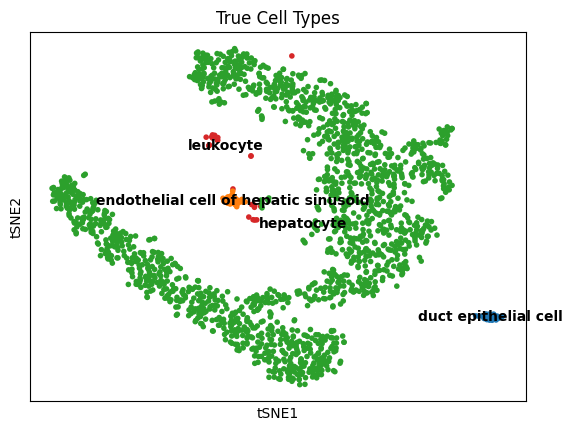

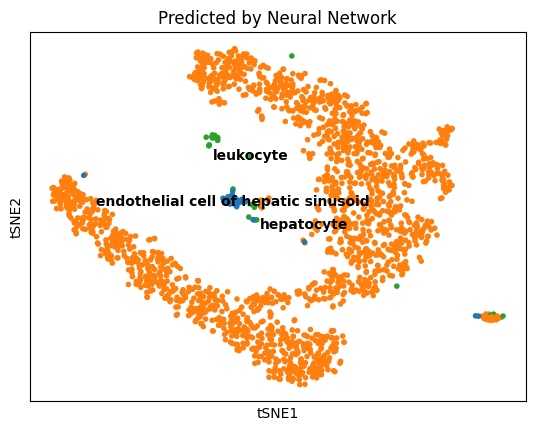

In [29]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


In [30]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")


TypeError: Categoricals can only be compared if 'categories' are the same.